# 04 | Mainland versions (without archipelagos)

Creates the PT + ES layers **without** the archipelagos and autonomous cities, and the postal code layers of the archipelagos only.

Regions removed (NUTS 2):

| Code | Region |
|---|---|
| PT20 | Região Autónoma dos Açores |
| PT30 | Região Autónoma da Madeira |
| ES53 | Illes Balears |
| ES63 | Ciudad de Ceuta |
| ES64 | Ciudad de Melilla |
| ES70 | Canarias |

**Output (layers in `data/processed/layers.gpkg`):** `PostalCodes2024_PT_ES_mainland`, `Localities2024_PT_ES_mainland`, `NUTS0_2024_PT_ES_mainland` to `NUTS3_2024_PT_ES_mainland`, `PostalCodes2024_PT_archipelagos`, `PostalCodes2024_ES_archipelagos`

## Setup

In [1]:
import sys
from pathlib import Path

# Make the src/ folder importable when running from the notebooks/ folder
sys.path.append(str(Path.cwd().parent))

import geopandas as gpd
import numpy as np
import pandas as pd

from src.utils import *

In [2]:
gdf_pc_PT_ES = load_layer("PostalCodes2024_PT_ES")
gdf_loc_PT_ES = load_layer("Localities2024_PT_ES")
gdf_nuts0_PT_ES = load_layer("NUTS0_2024_PT_ES")
gdf_nuts1_PT_ES = load_layer("NUTS1_2024_PT_ES")
gdf_nuts2_PT_ES = load_layer("NUTS2_2024_PT_ES")
gdf_nuts3_PT_ES = load_layer("NUTS3_2024_PT_ES")

## Postal codes of the archipelagos only

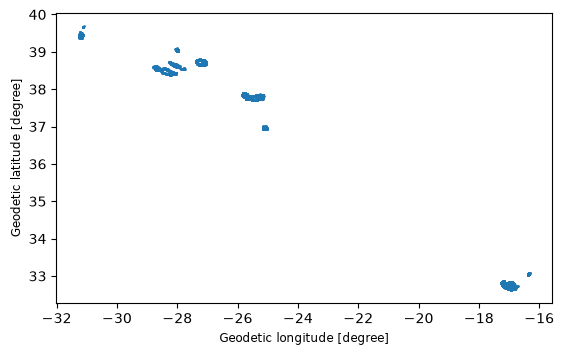

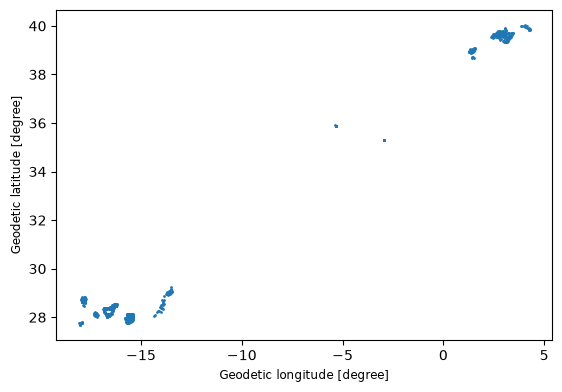

In [3]:
gdf_pc_PT_archipelagos = gdf_pc_PT_ES[gdf_pc_PT_ES["NUTS2_ID"].isin(["PT20", "PT30"])].copy()
gdf_pc_ES_archipelagos = gdf_pc_PT_ES[gdf_pc_PT_ES["NUTS2_ID"].isin(["ES53", "ES63", "ES64", "ES70"])].copy()

gdf_pc_PT_archipelagos.plot(markersize=1);
gdf_pc_ES_archipelagos.plot(markersize=1);

## Postal codes and localities – mainland

Postal codes: remove the records whose `NUTS2_ID` belongs to an archipelago.

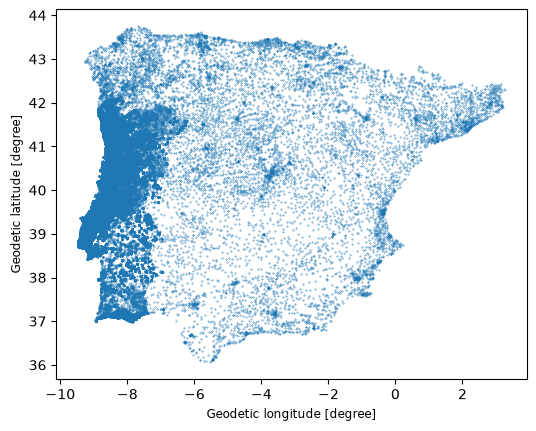

In [4]:
gdf_pc_PT_ES_mainland = gdf_pc_PT_ES[~gdf_pc_PT_ES["NUTS2_ID"].isin(ARCHIPELAGO_NUTS2_IDS)].copy()
gdf_pc_PT_ES_mainland.plot(markersize=0.1);

Localities: the LAU file has no NUTS code, so the localities removed are those that contain postal codes of the archipelagos.

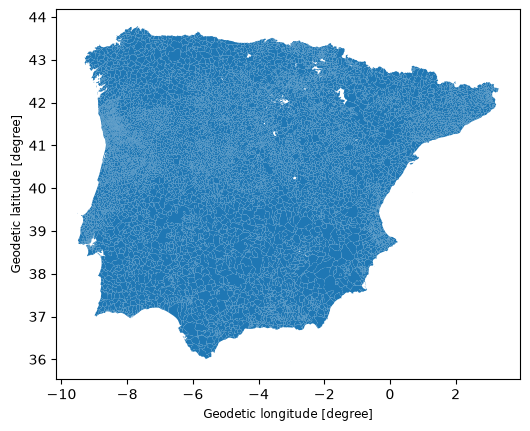

In [5]:
loc_ids_to_remove = pd.concat([gdf_pc_PT_archipelagos["LocalityID"], gdf_pc_ES_archipelagos["LocalityID"]]).unique()

gdf_loc_PT_ES_mainland = gdf_loc_PT_ES[~gdf_loc_PT_ES["LocalityID"].isin(loc_ids_to_remove)].copy()
gdf_loc_PT_ES_mainland.plot();

## NUTS – mainland

1. Select the NUTS 2 polygons of the archipelagos.
2. Dissolve them into a single polygon with `union_all()`.
3. Subtract that polygon from every NUTS 0, 1, 2 and 3 geometry (`difference`).
4. Remove the rows that become empty (regions that were entirely islands).
5. Recalculate the centroids, because the geometries changed.

**Note:** NUTS 2 is used to select the archipelagos, not NUTS 1, because the Spanish NUTS 1 region ES5 (Este) includes the Balearic Islands together with Catalonia and the Valencian Community. Filtering by NUTS 1 would remove part of the mainland. NUTS 3 was not used because it is too detailed: it would mean joining dozens of small units, which is slower and more fragile.

In [6]:
archipelagos = gdf_nuts2_PT_ES[gdf_nuts2_PT_ES["NUTS2_ID"].isin(ARCHIPELAGO_NUTS2_IDS)]
archipelagos_geometry = archipelagos.union_all()


def mainland_version(gdf):
    gdf_mainland = remove_archipelagos(gdf, archipelagos_geometry)
    gdf_mainland = gdf_mainland[~gdf_mainland.geometry.is_empty].copy()
    return add_centroids(gdf_mainland)


gdf_nuts0_PT_ES_mainland = mainland_version(gdf_nuts0_PT_ES)
gdf_nuts1_PT_ES_mainland = mainland_version(gdf_nuts1_PT_ES)
gdf_nuts2_PT_ES_mainland = mainland_version(gdf_nuts2_PT_ES)
gdf_nuts3_PT_ES_mainland = mainland_version(gdf_nuts3_PT_ES)

print("NUTS 2 regions before:", len(gdf_nuts2_PT_ES), "| after:", len(gdf_nuts2_PT_ES_mainland))

NUTS 2 regions before: 28 | after: 22


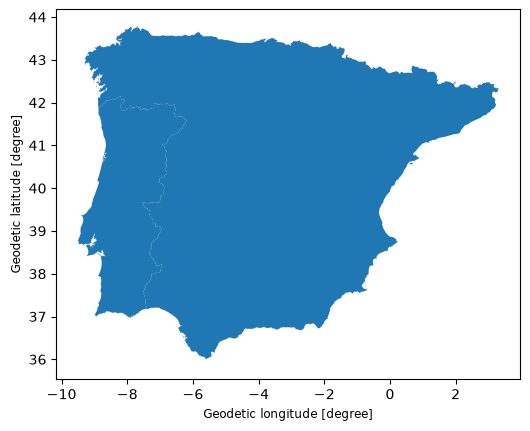

In [7]:
gdf_nuts0_PT_ES_mainland.plot();

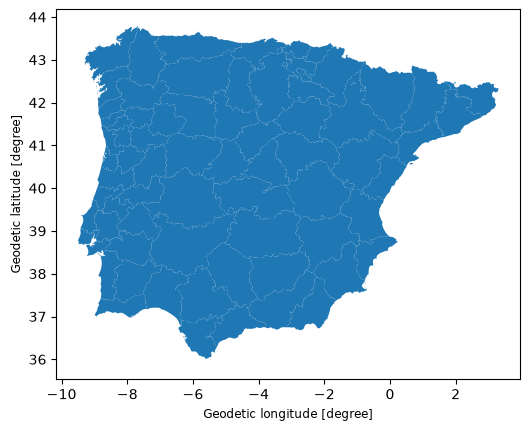

In [8]:
gdf_nuts3_PT_ES_mainland.plot();

## Save

In [9]:
save_layer(gdf_pc_PT_archipelagos, "PostalCodes2024_PT_archipelagos")
save_layer(gdf_pc_ES_archipelagos, "PostalCodes2024_ES_archipelagos")
save_layer(gdf_pc_PT_ES_mainland, "PostalCodes2024_PT_ES_mainland")
save_layer(gdf_loc_PT_ES_mainland, "Localities2024_PT_ES_mainland")
save_layer(gdf_nuts0_PT_ES_mainland, "NUTS0_2024_PT_ES_mainland")
save_layer(gdf_nuts1_PT_ES_mainland, "NUTS1_2024_PT_ES_mainland")
save_layer(gdf_nuts2_PT_ES_mainland, "NUTS2_2024_PT_ES_mainland")
save_layer(gdf_nuts3_PT_ES_mainland, "NUTS3_2024_PT_ES_mainland")

Saved layer 'PostalCodes2024_PT_archipelagos' (8885 rows)
Saved layer 'PostalCodes2024_ES_archipelagos' (566 rows)
Saved layer 'PostalCodes2024_PT_ES_mainland' (200378 rows)
Saved layer 'Localities2024_PT_ES_mainland' (10857 rows)
Saved layer 'NUTS0_2024_PT_ES_mainland' (2 rows)
Saved layer 'NUTS1_2024_PT_ES_mainland' (7 rows)
Saved layer 'NUTS2_2024_PT_ES_mainland' (22 rows)
Saved layer 'NUTS3_2024_PT_ES_mainland' (71 rows)


## Summary
* Created the postal code layers of the Portuguese and Spanish archipelagos.
* Removed the archipelagos from the postal codes (by `NUTS2_ID`) and from the localities (by the `LocalityID` of the archipelago postal codes).
* For the NUTS levels, subtracted the dissolved archipelago polygon from each geometry, removed the empty rows and recalculated the centroids.